# 12. Traffic simulation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/12_sim.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/12_sim.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-12.svg" alt="duckOSM notebook manual, chapter 12: Traffic simulation" width="100%">

| **You learn** | what a traffic simulation needs; the SUMO network with `to_sumo` and its options; how you read it with sumolib; `edge_map` from the SUMO ids to `edge_id`; a short SUMO run and its counts on the edges; the MATSim network, and MATSim lanes and signals |
|---|---|
| **Time** | about 3 minutes |
| **Extras** | `duckosm[sim,viz]` (the install cell installs them) |
| **Next** | [13. Transport planning](13_planning.md): GMNS networks, path4gmns and AequilibraE |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[sim,viz] @ {nightly_wheel()}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


## What a traffic simulation needs

A **traffic simulation** moves vehicles one by one on a road network and gives the result: the count of vehicles on
each road, their speed, the queues and the travel times. It needs three parts:

| Part | What it is | Where it comes from |
|---|---|---|
| the network | the roads, their lanes and speeds, and the turns at each junction | duckOSM: `to_sumo` or `to_matsim` |
| the demand | the trips: where each vehicle starts, where it goes, and when | your origin-destination data, or random trips for a test |
| the simulator | the program that moves the vehicles | SUMO (microscopic: each vehicle and each lane) or MATSim (agents and their daily plans) |

The module `duckosm.sim` makes the network for the two simulators, and gives you the way back from their results to
the duckOSM edges.

| Simulator | The duckOSM call | The file | Use it for |
|---|---|---|---|
| SUMO | `to_sumo` | `network.net.xml` (and the plain XML files) | each vehicle and lane, traffic lights, junctions |
| MATSim | `to_matsim` | `network.xml.gz` | large areas, daily plans of agents, many iterations |

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/sim-loop.svg" alt="The loop of a simulation: the duckOSM network, the SUMO network, the demand, the simulation, and the results back on the edges" width="100%">

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> The id of each SUMO edge and of each MATSim link is the duckOSM `edge_id`. So the results of a simulation join back to the network, to your own data (chapter 4) and to the map, with no table of ids to keep.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> The page [duckOSM for traffic simulation users](../compare/for-simulation-users.md) compares each call with netconvert, sumolib and MATSim's own tools.

## Build the network

The chapter uses the driving network of Monaco. The extra `sim` installs SUMO (with its program `netconvert`) and
sumolib.

In [2]:
net = duckosm.network(osm_id=2220322, modes=["driving"], name="monaco")    # get and build the driving network of Monaco
net.driving                                                                # the card of the driving mode

cut: 34461 nodes, 5685 ways, 339 relations

Output: ~/.cache/duckosm/work/monaco-20261120-213816-3fc4/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5


The driving network of Monaco has 2840 edges and 1768 nodes, 96.2 km of roads.

## The SUMO network: `to_sumo`

`net.driving.to_sumo(out_dir)` (the same as `duckosm.sim.to_sumo(net.driving, out_dir)`) writes the network of one
mode in SUMO's **plain XML** files, then runs SUMO's `netconvert` on them to make the `.net.xml` that SUMO reads.

| File | What it has |
|---|---|
| `network.nod.xml` | the nodes: one SUMO junction for each duckOSM node |
| `network.edg.xml` | the edges: the id (the `edge_id`), the lanes, the speed, the shape |
| `network.con.xml` | the connections: the turns that are allowed at each junction, from `driving.edge_graph`, so the turn restrictions apply |
| `network.netccfg` | the options of `netconvert` |
| `network.net.xml` | the network that SUMO reads, made by `netconvert` |

The call gives a dict with the path of each file and the counts.

| Argument | Default | What it does |
|---|---|---|
| `net_name` | `"network"` | the first part of each file name |
| `run_netconvert` | `True` | `False`: only the plain XML files, with no SUMO program |
| `connections` | `True` | `False`: no `.con.xml`, so netconvert chooses the turns itself |
| `config` | none | your own netconvert options (a `.netccfg` file) |

In [3]:
files = net.driving.to_sumo("out/sumo")                     # the plain XML files and network.net.xml
{k: str(v) for k, v in files.items()}                       # the files and the counts

SUMO out/sumo: done in 0.4 s

running: netconvert -c out/sumo/network.netccfg


{'nod': 'out/sumo/network.nod.xml',
 'edg': 'out/sumo/network.edg.xml',
 'n_nodes': '1768',
 'n_edges': '2840',
 'n_connections': '5082',
 'con': 'out/sumo/network.con.xml',
 'netccfg': 'out/sumo/network.netccfg',
 'net': 'out/sumo/network.net.xml'}

The SUMO
network has 1768 nodes and 2840 edges, the same numbers as the driving network, and 5082 connections. `net` is the
path of `network.net.xml`, the file that SUMO reads.

### The netconvert options

duckOSM gives `netconvert` a small set of options, `duckosm.sim.DEFAULT_NETCFG`. They keep each duckOSM edge as one
SUMO edge with the same id.

In [4]:
duckosm.sim.DEFAULT_NETCFG                                  # the options that to_sumo gives netconvert

{'proj.utm': 'true',
 'geometry.remove': 'false',
 'junctions.join': 'false',
 'no-turnarounds.except-deadend': 'true',
 'numerical-ids': 'false'}

The five options:

| Option | Value | Why |
|---|---|---|
| `proj.utm` | `true` | the nodes are in lon and lat, and netconvert projects them to the UTM zone of the area |
| `geometry.remove` | `false` | netconvert must not join two edges into one, so each SUMO edge is one `edge_id` |
| `junctions.join` | `false` | netconvert must not join near nodes into one junction |
| `no-turnarounds.except-deadend` | `true` | no U-turns, except at a dead end |
| `numerical-ids` | `false` | the ids stay as duckOSM writes them |

### Your own options: `config=`

`config=` takes your own `.netccfg` file, and `netconvert` then uses it in place of the defaults. This cell writes a
file with the defaults and one change, `geometry.remove = true`, to show why the default is `false`.

In [5]:
cfg = {**duckosm.sim.DEFAULT_NETCFG, "geometry.remove": "true"}           # the defaults, with one change
with open("merge.netccfg", "w") as f:                                      # a netconvert config file
    f.write("<configuration>\n" + "".join(f'  <{k} value="{v}"/>\n' for k, v in cfg.items()) + "</configuration>\n")
merged = net.driving.to_sumo("out/sumo_merged", config="merge.netccfg")    # netconvert with your options
len(duckosm.sim.edge_map(merged)), files["n_edges"]                     # the edges with their edge_id in SUMO, of all

SUMO out/sumo_merged: done in 0.3 s

running: netconvert -c merge.netccfg --node-files out/sumo_merged/network.nod.xml --edge-files out/sumo_merged/network.edg.xml --output-file out/sumo_merged/network.net.xml --connection-files out/sumo_merged/network.con.xml


(1615, 2840)

With `geometry.remove = true`, only 1615 of the 2840 edges keep their `edge_id` as a
SUMO edge. netconvert joined the other 1225 edges into their neighbors.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> Keep `geometry.remove` set to `false`. With `true`, netconvert joins the edges between two junctions into one SUMO edge, and keeps only the id of the first edge. The other edges then have no SUMO edge, and their results are lost.

### Only the plain XML files

`run_netconvert=False` writes the plain XML files and does not run `netconvert`. Use it when SUMO is on another
machine, or when you run `netconvert` yourself with more options.

In [6]:
plain = net.driving.to_sumo("out/sumo_plain", run_netconvert=False)       # no netconvert, no .net.xml
sorted(k for k in plain if not k.startswith("n_"))                          # the files

SUMO out/sumo_plain: done in 0.1 s

['con', 'edg', 'nod']

The dict has the three plain XML files (`nod`, `edg`, `con`) and no `net`. Run
`netconvert --node-files ... --edge-files ... --connection-files ...` on them to make the network.

## Read the network with sumolib: `sumo_net`

`duckosm.sim.sumo_net(files)` reads the `.net.xml` with sumolib (`sumolib.net.readNet`), with the internal edges of
the junctions. It takes the path of a `.net.xml` or the dict of `to_sumo`. The result is a `sumolib.net.Net`: use
sumolib's own calls on it.

In [7]:
sn = duckosm.sim.sumo_net(files)             # the .net.xml read with sumolib
{"SUMO edges": len(sn.getEdges(withInternal=False)), "junctions": len(sn.getNodes()),
 "traffic lights": len(sn.getTrafficLights()), "duckOSM edges": int(net.driving.summary().edges[0])}    # the numbers

{'SUMO edges': 2840,
 'junctions': 1768,
 'traffic lights': 0,
 'duckOSM edges': 2840}

Sumolib reads 2840 SUMO edges and 1768 junctions: one SUMO edge for each duckOSM edge,
and one junction for each node. Monaco has no traffic lights in this SUMO network.

In [8]:
e = sn.getEdges(withInternal=False)[0]                                     # one SUMO edge
{"id": e.getID(), "lanes": e.getLaneNumber(), "speed m/s": e.getSpeed(), "length m": round(e.getLength(), 1),
 "from": e.getFromNode().getID(), "to": e.getToNode().getID()}             # what SUMO knows of it

{'id': '1003228148726728921',
 'lanes': 1,
 'speed m/s': 5.56,
 'length m': 47.3,
 'from': '12850925908',
 'to': '4437632778'}

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The id of the SUMO edge is an `edge_id`, and the ids of its two junctions are OSM node ids. The edge has 1 lane, 47.3 m. The speed is 5.56 m/s (20 km/h), from the `maxspeed_kmh` of the edge.

## From the SUMO ids to the edge ids: `edge_map`

`duckosm.sim.edge_map(path)` gives a DataFrame with two columns: `id`, the id of each edge in the file (text), and
`edge_id`, its duckOSM `edge_id` (a number). duckOSM writes the `edge_id` as the SUMO id, so the two are the same
in a network of `to_sumo`. When a tool changes an id, `edge_map` still finds the `edge_id`:

| The id in the file | `edge_map` gives |
|---|---|
| `123` | one row: 123 |
| `123#1` (netconvert cut the edge 123) | one row: 123 |
| `123+456` (two edges joined) | two rows: 123 and 456 |
| `:junction_0` (an internal edge of a junction) | no row |

`path` can be a `.net.xml`, an `.edg.xml`, the dict of `to_sumo`, or a MATSim network (section "MATSim" below).

In [9]:
edges = duckosm.sim.edge_map(files)                         # the SUMO id and the edge_id of each SUMO edge
print(len(edges), "rows;", int((edges.id != edges.edge_id.astype(str)).sum()), "ids that netconvert changed")
edges.head(3)

2840 rows; 0 ids that netconvert changed


,id,edge_id
0,1003228148726728921,1003228148726728921
1,1014480835261600237,1014480835261600237
2,1015158544797938083,1015158544797938083


`edge_map` gives 2840 rows, one for each SUMO edge, and netconvert changed no id. So
here `id` and `edge_id` are the same number, as text and as an integer.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> Join the output of a simulation on `id`, then the network on `edge_id`. The next section does this.

## Run SUMO

SUMO needs the demand. For a test, SUMO's tool `randomTrips.py` makes random trips between random edges. This cell
makes one trip each second for 900 s (15 minutes), and asks SUMO to write an **edgeData** file: for each edge, the
number of vehicles that entered it, and their speed and time on it. Then `sumo` runs the trips for 30 minutes.

| Program | Arguments | What it does |
|---|---|---|
| `randomTrips.py` | `-n` the network, `-e 900`, `-p 1`, `--validate` | 900 random trips, one each second, each one with a possible route |
| `sumo` | `-n` the network, `-r` the trips, `-a` the edgeData file, `--end 1800` | the simulation, 30 minutes |

`sumo.SUMO_HOME` is the folder of the SUMO of the extra `sim`.

In [10]:
import subprocess, sys
import sumo                                                              # the SUMO of the extra sim

subprocess.run([sys.executable, f"{sumo.SUMO_HOME}/tools/randomTrips.py", "-n", str(files["net"]),
                "-o", "out/sumo/trips.xml", "-r", "out/sumo/routes.rou.xml", "-e", "900", "-p", "1", "--validate", "--seed", "1"],
               check=True, capture_output=True)                          # a trip each second, for 900 s
open("out/sumo/edgedata.add.xml", "w").write(
    '<additional><edgeData id="counts" file="edgedata.xml"/></additional>')    # the counts of each edge
subprocess.run([f"{sumo.SUMO_HOME}/bin/sumo", "-n", str(files["net"]), "-r", "out/sumo/trips.xml",
                "-a", "out/sumo/edgedata.add.xml", "--no-step-log", "--end", "1800", "--seed", "1"],
               check=True, capture_output=True).returncode               # the simulation, 30 minutes; 0: no error

0

The return code 0 tells that SUMO ran with no error. SUMO wrote
`out/sumo/edgedata.xml`, with one `<edge>` element for each SUMO edge.

## Join the counts back to the edges

`pandas.read_xml` reads the edgeData file: one row for each SUMO edge, with the column `entered` (the vehicles that
entered the edge). The merge on `id` with `edge_map` gives each row its `edge_id`. The sum by `edge_id` puts the parts
of an edge together when netconvert cut it.

In [11]:
import pandas as pd                                                      # to read the output of SUMO

counts = pd.read_xml("out/sumo/edgedata.xml", xpath=".//edge", parser="etree", dtype={"id": str})    # one row for each SUMO edge
cars = counts.merge(edges, on="id").groupby("edge_id").entered.sum()               # the cars of each edge_id
cars.describe()                                                                    # the counts

count    2840.000000
mean       18.722535
std        25.666826
min         0.000000
25%         1.000000
50%         7.000000
75%        25.000000
max       145.000000
Name: entered, dtype: float64

Each of the 2840 edges has a count. Half of the edges have 7 cars or fewer in the 30
minutes, and some have none. The busiest edge has 145 cars.

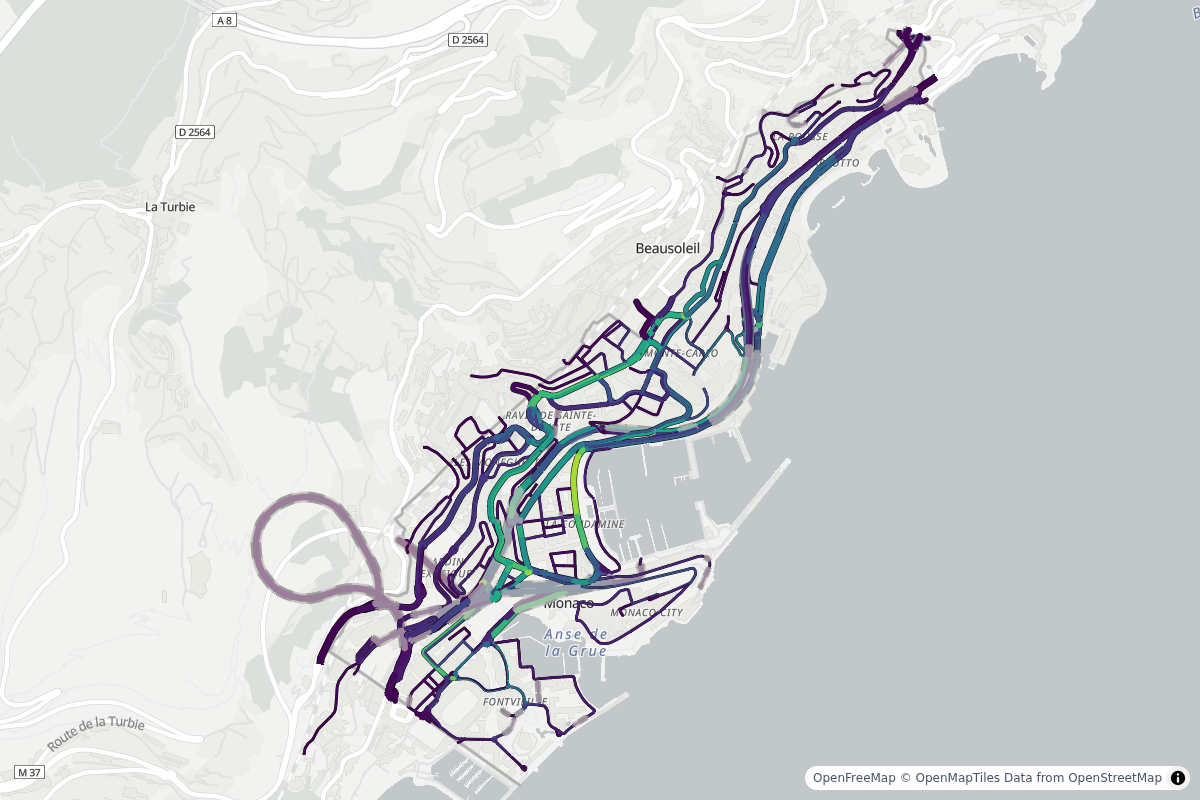

In [12]:
net.driving.map(color_by=cars)    # the edges colored by the number of cars (a picture here; live when you run it)

The main roads and the tunnels have the most cars (green and yellow): the random trips cross Monaco
on them. The small streets have few cars or none.

In [13]:
top = net.edges(where=f"edge_id IN ({','.join(map(str, cars.nlargest(3).index))})")[["edge_id", "name", "highway"]]
top.assign(cars=top.edge_id.map(cars)).sort_values("cars", ascending=False)        # the three edges with the most cars

,edge_id,name,highway,cars
1,4230741665531352064,Place d'Armes,secondary,145
0,858818552680309172,Giratoire Aureglia,primary,126
2,4551155039579564675,Boulevard Albert 1er,secondary,126


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The busiest edges are on the Place d'Armes (145 cars), the roundabout Giratoire Aureglia (126) and the Boulevard Albert 1er (126): primary and secondary roads. The names come from the duckOSM edges, through the `edge_id`.

## MATSim

MATSim simulates agents: each agent has a plan for the day, and MATSim improves the plans over many iterations.
`net.driving.to_matsim(out_path)` (the same as `duckosm.sim.to_matsim`) writes MATSim's `network.xml`.

| Argument | Default | What it does |
|---|---|---|
| `mode` | the mode of the view | one mode, or a list of modes (one network, each link with its modes) |
| `crs` | the UTM zone of the area | the projected CRS of the coordinates (MATSim needs metres) |
| `gzip` | `True` | write `network.xml.gz` |

The id of each MATSim link is the `edge_id` too, so `edge_map` reads the MATSim network in the same way: give it the
`network.xml` or `network.xml.gz`.

In [14]:
stats = net.driving.to_matsim("out/matsim_network.xml.gz")              # the MATSim network
links = duckosm.sim.edge_map("out/matsim_network.xml.gz")              # the link id and the edge_id of each link
print(stats)                                                           # the counts and the CRS
len(links), set(links.edge_id) == set(net.edges().edge_id)             # one link for each edge

MATSim out/matsim_network.xml.gz: done in 0.1 s

{'nodes': 1768, 'links': 2840, 'crs': 'EPSG:32632'}


(2840, True)

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The MATSim network has 1768 nodes and 2840 links, in the CRS EPSG:32632 (UTM zone 32N, the zone of Monaco). `edge_map` reads 2840 links, and their ids are the edge ids of the network.

### MATSim lanes and signals: `to_matsim_lanes`

MATSim can also simulate lanes and traffic signals. `duckosm.sim.to_matsim_lanes(gmns_db, out_dir)` writes MATSim's
`lanes.xml` and the signal files (`signalSystems.xml`, `signalGroups.xml`, `signalControl.xml`). It reads the lanes
and the movements of a GMNS database, which `to_gmns` makes (chapter 13 tells more about GMNS).

| Argument | Default | What it does |
|---|---|---|
| `mode` | `"driving"` | the mode of the GMNS database |
| `signals` | `True` | also the signal files |
| `cycle_s` | `90` | the cycle time of each signal, in seconds |

In [15]:
import os
net.driving.to_gmns("out/gmns.duckdb")                                     # the GMNS tables (chapter 13)
lanes = duckosm.sim.to_matsim_lanes("out/gmns.duckdb", "out/matsim")       # lanes.xml and the signal files
print(lanes)
sorted(os.listdir("out/matsim"))                                           # the files

GMNS out/gmns.duckdb: done in 26.4 s

{'lanes_links': 2832, 'signal_systems': 1}


['lanes.xml', 'signalControl.xml', 'signalGroups.xml', 'signalSystems.xml']

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The GMNS export takes most of the time of the cell, because it runs netconvert for the lanes. `lanes.xml` has lanes for 2832 links, and the signal files have one signal system: the one signal of the GMNS tables of Monaco.

## Try it yourself

**1.** Make the SUMO network with no `.con.xml` (`connections=False`), and count the files.

<details><summary>Show the answer</summary>

```python
f = net.driving.to_sumo("out/sumo_nocon", connections=False)
sorted(k for k in f if not k.startswith("n_"))
```
</details>

**2.** Find the five edges with the highest mean speed in the SUMO run. The edgeData column `speed` is in m/s.

<details><summary>Show the answer</summary>

```python
speed = counts.merge(edges, on="id").groupby("edge_id").speed.mean()
speed.nlargest(5) * 3.6                                                     # km/h
```
</details>

**3.** Write one MATSim network for driving and walking. Build a network with the two modes first.

<details><summary>Show the answer</summary>

```python
both = duckosm.network(osm_id=2220322, modes=["driving", "walking"], name="monaco_dw")
duckosm.sim.to_matsim(both, "out/matsim_dw.xml.gz", mode=["driving", "walking"])
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| traffic simulation | a program that moves vehicles one by one on a road network |
| demand | the trips of a simulation: start, end and time |
| SUMO | Simulation of Urban MObility, a microscopic traffic simulator |
| netconvert | the SUMO program that makes a `.net.xml` from the plain XML files |
| plain XML | SUMO's simple files of nodes, edges and connections |
| connection | a turn from one lane of an edge to a lane of the next edge |
| internal edge | a short SUMO edge inside a junction, for one turn |
| edgeData | a SUMO output with the counts and speeds of each edge |
| MATSim | an agent-based simulator of daily plans |
| sumolib | SUMO's Python library to read and use its files |

## Summary

| Call | Does |
|---|---|
| `net.driving.to_sumo(out_dir, ...)`, `duckosm.sim.to_sumo(...)` | the SUMO network, with the `edge_id` as the id of each SUMO edge |
| `duckosm.sim.DEFAULT_NETCFG` | the netconvert options of `to_sumo` |
| `duckosm.sim.sumo_net(files)` | the `.net.xml` read with sumolib |
| `duckosm.sim.edge_map(path)` | the SUMO or MATSim id of each edge or link, and its `edge_id` |
| `net.driving.to_matsim(out_path)`, `duckosm.sim.to_matsim(...)` | the MATSim network |
| `duckosm.sim.to_matsim_lanes(gmns_db, out_dir)` | MATSim lanes and signals, from a GMNS database |

The reference: [duckosm.sim](../reference/sdk/sim.md). **Next:** [13. Transport planning](13_planning.md), GMNS networks, path4gmns and AequilibraE.